In [3]:
import pandas as pd

# Load the file in chunks to see what labels actually exist
print("Scanning dataset labels...")
df_test = pd.read_csv('iot23_combined_new.csv', usecols=['label'])
print("Total rows:", len(df_test))
print("\nUnique labels found:")
print(df_test['label'].value_counts())

Scanning dataset labels...
Total rows: 6046623

Unique labels found:
label
PartOfAHorizontalPortScan     3389036
Okiru                         1313012
Benign                         688812
DDoS                           638506
C&C                             15286
C&C-HeartBeat                    1332
Attack                            538
C&C-FileDownload                   46
C&C-Torii                          30
FileDownload                       13
C&C-HeartBeat-FileDownload          8
Okiru-Attack                        3
C&C-Mirai                           1
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

print("Loading 50,000 random rows from the 6 million row dataset...")
# Taking a random 50k sample 
df = pd.read_csv('iot23_combined_new.csv').sample(n=50000, random_state=42)

#Drop Spoofable Identifiers (Phase 2 methodology)
drop_cols = ['ts', 'uid', 'id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p']
df = df.drop(columns=drop_cols, errors='ignore')

#Clean Zeek log hyphens and handle missing values
df.replace('-', np.nan, inplace=True)
df.fillna(0, inplace=True)

# FIX: Binary Labeling based on your exact dataset labels!
# If it is 'Benign', label it 0. Everything else (Okiru, DDoS, PortScan) becomes 1.
df['binary_label'] = df['label'].apply(lambda x: 0 if x == 'Benign' else 1)
df = df.drop(columns=['label'])

# One-Hot Encode Categorical Features
cat_cols = ['proto', 'service', 'conn_state', 'history']
cat_cols_existing = [c for c in cat_cols if c in df.columns]
df = pd.get_dummies(df, columns=cat_cols_existing)

# Stratified Split (70 Train / 15 Val / 15 Test)
X = df.drop(columns=['binary_label'])
y = df['binary_label']

# Split off 30% (Val + Test)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
# Split the remaining into Train (70%) and Val (15% overall)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.214, stratify=y_temp, random_state=42)

print(f"\nOriginal Training set shape: {X_train.shape}")
print(f"Attack samples before SMOTE (1): {sum(y_train)}")
print(f"Benign samples before SMOTE (0): {len(y_train) - sum(y_train)}")

# Apply SMOTE ONLY to training data to prevent data leakage
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(f"\nTraining set shape after SMOTE: {X_train_sm.shape}")
print(f"Attack samples after SMOTE (1): {sum(y_train_sm)}")
print(f"Benign samples after SMOTE (0): {len(y_train_sm) - sum(y_train_sm)}")

#Scale Data (Fit on Train, transform Val/Test to prevent leakage)
scaler = StandardScaler()
X_train_sm = pd.DataFrame(scaler.fit_transform(X_train_sm), columns=X_train_sm.columns)
X_val = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print("\nData preprocessing complete! Ready for model training.")

Loading 50,000 random rows from the 6 million row dataset...


C:\Users\humna\AppData\Local\Temp\ipykernel_6120\2617237700.py:9: DtypeWarning: Columns (9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('iot23_combined_new.csv').sample(n=50000, random_state=42)
C:\Users\humna\AppData\Local\Temp\ipykernel_6120\2617237700.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace('-', np.nan, inplace=True)



Original Training set shape: (27510, 42)
Attack samples before SMOTE (1): 24351
Benign samples before SMOTE (0): 3159

Training set shape after SMOTE: (48702, 42)
Attack samples after SMOTE (1): 24351
Benign samples after SMOTE (0): 24351

Data preprocessing complete! Ready for model training.


In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
import pandas as pd

#Initialize the 4 Baseline Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_jobs=-1, random_state=42)
}

results = []

print("Training Baseline Models... This will take a minute.\n")
print("-" * 60)

X_train_np = X_train_sm.values
y_train_np = y_train_sm.values
X_test_np = X_test.values
y_test_np = y_test.values

#Train and Evaluate Each Model
for name, model in models.items():
    print(f"Training {name}...")
    
    # Train the model on pure numpy arrays
    start_train = time.time()
    model.fit(X_train_np, y_train_np)
    
    # Predict on pure numpy arrays
    start_infer = time.time()
    y_pred = model.predict(X_test_np)
    y_prob = model.predict_proba(X_test_np)[:, 1] # Get probabilities for ROC-AUC
    infer_time = time.time() - start_infer
    
    # Calculate Phase 2 Evaluation Metrics
    macro_f1 = f1_score(y_test_np, y_pred, average='macro')
    roc_auc = roc_auc_score(y_test_np, y_prob)
    
    # Calculate False Positive Rate (FPR) from Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(y_test_np, y_pred).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    # Calculate per-sample inference time in milliseconds
    per_sample_latency_ms = (infer_time / len(X_test_np)) * 1000
    
    print(f"  -> Macro-F1: {macro_f1:.4f}")
    print(f"  -> ROC-AUC:  {roc_auc:.4f}")
    print(f"  -> FPR:      {fpr:.4f}")
    print(f"  -> Latency:  {per_sample_latency_ms:.4f} ms/sample")
    print("-" * 60)
    
    # Store results for the visualizations later
    results.append({
        "Model": name,
        "Macro-F1": macro_f1,
        "ROC-AUC": roc_auc,
        "FPR": fpr,
        "Latency (ms)": per_sample_latency_ms
    })

results_df = pd.DataFrame(results)
print("\nBaseline Training Complete! Summary Table:")
print(results_df.to_string(index=False))

Training Baseline Models... This will take a minute.

------------------------------------------------------------
Training Logistic Regression...
  -> Macro-F1: 0.6905
  -> ROC-AUC:  0.6937
  -> FPR:      0.6109
  -> Latency:  0.0000 ms/sample
------------------------------------------------------------
Training Random Forest...
  -> Macro-F1: 0.8562
  -> ROC-AUC:  0.9274
  -> FPR:      0.2015
  -> Latency:  0.0156 ms/sample
------------------------------------------------------------
Training XGBoost...
  -> Macro-F1: 0.8975
  -> ROC-AUC:  0.9467
  -> FPR:      0.2375
  -> Latency:  0.0019 ms/sample
------------------------------------------------------------
Training LightGBM...
[LightGBM] [Info] Number of positive: 24351, number of negative: 24351
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004543 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
import pandas as pd

print("Initializing PyTorch Environment...")

#Convert Numpy arrays to PyTorch Tensors
X_train_tensor = torch.FloatTensor(X_train_np)
y_train_tensor = torch.FloatTensor(y_train_np).unsqueeze(1) # Reshape for binary classification
X_test_tensor = torch.FloatTensor(X_test_np)
y_test_tensor = torch.FloatTensor(y_test_np).unsqueeze(1)

#Create DataLoader for efficient batch training
# Batch size 128 is a good balance for CPU memory and training speed
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

#Define the Phase 2 "Compact MLP" Architecture
class CompactMLP(nn.Module):
    def __init__(self, input_dim):
        super(CompactMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2), # Prevents overfitting
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid() # Outputs a probability between 0 and 1
        )
        
    def forward(self, x):
        return self.network(x)

#Get the number of features (columns) from our data
input_size = X_train_tensor.shape[1]
mlp_model = CompactMLP(input_dim=input_size)

# 4. Setup Loss Function and Optimizer
criterion = nn.BCELoss() # Binary Cross Entropy Loss
optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)

print("\nTraining Proposed Compact MLP (20 Epochs)...")
print("-" * 60)
start_train = time.time()

#Training Loop
epochs = 20
mlp_model.train()
for epoch in range(epochs):
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = mlp_model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    
    # Print progress every 5 epochs so you know it hasn't frozen
    if (epoch + 1) % 5 == 0:
        print(f"  -> Epoch {epoch+1}/{epochs} | Loss: {epoch_loss/len(train_loader):.4f}")

train_time = time.time() - start_train

#Evaluation on Unseen Test Set
print("-" * 60)
print("Evaluating Proposed MLP...")
mlp_model.eval()
start_infer = time.time()
with torch.no_grad():
    y_prob_tensor = mlp_model(X_test_tensor)
    y_pred_tensor = (y_prob_tensor >= 0.5).float()
infer_time = time.time() - start_infer

#Convert PyTorch tensors back to Numpy for scikit-learn metrics
y_prob_mlp = y_prob_tensor.numpy()
y_pred_mlp = y_pred_tensor.numpy()

#Calculate Metrics
macro_f1_mlp = f1_score(y_test_np, y_pred_mlp, average='macro')
roc_auc_mlp = roc_auc_score(y_test_np, y_prob_mlp)

tn, fp, fn, tp = confusion_matrix(y_test_np, y_pred_mlp).ravel()
fpr_mlp = fp / (fp + tn) if (fp + tn) > 0 else 0

per_sample_latency_mlp = (infer_time / len(X_test_np)) * 1000

print(f"  -> Macro-F1: {macro_f1_mlp:.4f}")
print(f"  -> ROC-AUC:  {roc_auc_mlp:.4f}")
print(f"  -> FPR:      {fpr_mlp:.4f}")
print(f"  -> Latency:  {per_sample_latency_mlp:.4f} ms/sample")
print("-" * 60)

#Add Proposed Model to the Results DataFrame
results.append({
    "Model": "Proposed Compact MLP",
    "Macro-F1": macro_f1_mlp,
    "ROC-AUC": roc_auc_mlp,
    "FPR": fpr_mlp,
    "Latency (ms)": per_sample_latency_mlp
})

#Re-create and print the final updated DataFrame
final_results_df = pd.DataFrame(results)
print("\nPhase 3: Final Model Comparison Table:")
print(final_results_df.to_string(index=False))

Initializing PyTorch Environment...

Training Proposed Compact MLP (20 Epochs)...
------------------------------------------------------------
  -> Epoch 5/20 | Loss: 0.4998
  -> Epoch 10/20 | Loss: 0.4914
  -> Epoch 15/20 | Loss: 0.4892
  -> Epoch 20/20 | Loss: 0.4868
------------------------------------------------------------
Evaluating Proposed MLP...
  -> Macro-F1: 0.6904
  -> ROC-AUC:  0.7135
  -> FPR:      0.6115
  -> Latency:  0.0006 ms/sample
------------------------------------------------------------

Phase 3: Final Model Comparison Table:
               Model  Macro-F1  ROC-AUC      FPR  Latency (ms)
 Logistic Regression  0.690534 0.693689 0.610918      0.000000
       Random Forest  0.856217 0.927407 0.201510      0.015552
             XGBoost  0.897549 0.946710 0.237515      0.001926
            LightGBM  0.910632 0.946719 0.252613      0.018172
Proposed Compact MLP  0.690352 0.713525 0.611498      0.000646


Calculating SHAP math natively...


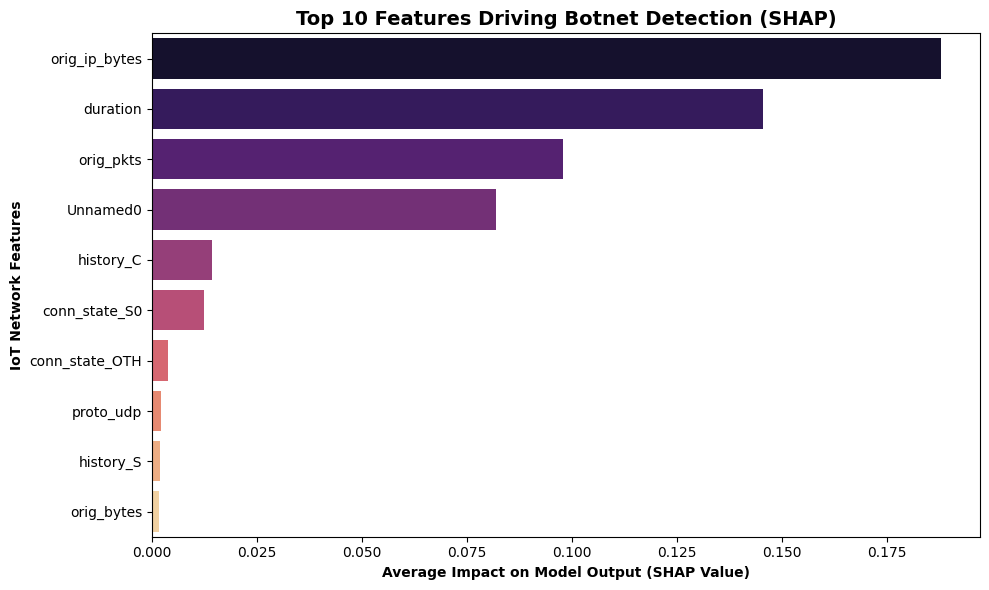


--- SHAP EXTRACTION COMPLETE ---
Your Top 3 Features to use in the MLP Ablation Study are:
1. orig_ip_bytes
2. duration
3. orig_pkts


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

print("Calculating SHAP math natively...")

#Grab the Random Forest model and a 1000-row sample
rf_model = models["Random Forest"]
X_test_sample_df = X_test.sample(n=1000, random_state=42)

#Feed pure numpy arrays to SHAP
explainer = shap.TreeExplainer(rf_model)
shap_vals = explainer.shap_values(X_test_sample_df.values)

#Handle SHAP shape variations to extract the 'Attack' class
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]
elif len(shap_vals.shape) == 3:
    # If it's a 3D array (samples, features, classes), grab index 1 for attacks
    shap_vals = shap_vals[:, :, 1]

#Calculate the average impact and FORCE it to be 1-dimensional
mean_abs_shap = np.abs(shap_vals).mean(axis=0)
mean_abs_shap = np.array(mean_abs_shap).flatten()

#Manually map the raw math back to your Pandas column names
shap_df = pd.DataFrame({
    'Feature': X_test.columns,
    'SHAP Importance': mean_abs_shap
})

# Sort to get the top 10 most important features
top_10_shap = shap_df.sort_values(by='SHAP Importance', ascending=False).head(10)

# 6. Draw the chart using Seaborn (100% guaranteed to render)
plt.figure(figsize=(10, 6))
sns.barplot(x='SHAP Importance', y='Feature', data=top_10_shap, palette='magma')
plt.title("Top 10 Features Driving Botnet Detection (SHAP)", fontweight='bold', fontsize=14)
plt.xlabel("Average Impact on Model Output (SHAP Value)", fontweight='bold')
plt.ylabel("IoT Network Features", fontweight='bold')
plt.tight_layout()
plt.show()

#Print the top 3 features for the final Ablation step
print("\n--- SHAP EXTRACTION COMPLETE ---")
print("Your Top 3 Features to use in the MLP Ablation Study are:")
top_3_list = top_10_shap['Feature'].head(3).tolist()
for i, feature in enumerate(top_3_list, 1):
    print(f"{i}. {feature}")

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
import pandas as pd

#Isolate the Top 3 Features identified by SHAP
top_3_features = ['orig_ip_bytes', 'duration', 'orig_pkts']
print(f"Starting Final Ablation Study using ONLY: {top_3_features}\n")

# Slice our original Pandas DataFrames to keep only these 3 columns, then convert to Numpy
X_train_abl = X_train_sm[top_3_features].values
X_test_abl = X_test[top_3_features].values

#Convert to PyTorch Tensors
X_train_tensor_abl = torch.FloatTensor(X_train_abl)
y_train_tensor_abl = torch.FloatTensor(y_train_sm.values).unsqueeze(1)
X_test_tensor_abl = torch.FloatTensor(X_test_abl)
y_test_tensor_abl = torch.FloatTensor(y_test.values).unsqueeze(1)

# 3. Create DataLoader
train_dataset_abl = TensorDataset(X_train_tensor_abl, y_train_tensor_abl)
train_loader_abl = DataLoader(train_dataset_abl, batch_size=128, shuffle=True)

# Re-Initialize the Compact MLP (Notice input_dim=3 now instead of 42!)
# Re-defining the class here just to be safe
class CompactMLP(nn.Module):
    def __init__(self, input_dim):
        super(CompactMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.network(x)

ablated_mlp_model = CompactMLP(input_dim=3)
criterion = nn.BCELoss()
optimizer = optim.Adam(ablated_mlp_model.parameters(), lr=0.001)

print("Training Optimized MLP (20 Epochs)...")
print("-" * 60)
start_train = time.time()

#Training Loop
epochs = 20
ablated_mlp_model.train()
for epoch in range(epochs):
    epoch_loss = 0
    for batch_X, batch_y in train_loader_abl:
        optimizer.zero_grad()
        predictions = ablated_mlp_model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    
    if (epoch + 1) % 5 == 0:
        print(f"  -> Epoch {epoch+1}/{epochs} | Loss: {epoch_loss/len(train_loader_abl):.4f}")

train_time = time.time() - start_train

#Evaluation
print("-" * 60)
print("Evaluating Optimized MLP...")
ablated_mlp_model.eval()
start_infer = time.time()
with torch.no_grad():
    y_prob_tensor_abl = ablated_mlp_model(X_test_tensor_abl)
    y_pred_tensor_abl = (y_prob_tensor_abl >= 0.5).float()
infer_time = time.time() - start_infer

#Convert back to Numpy for metrics
y_prob_abl = y_prob_tensor_abl.numpy()
y_pred_abl = y_pred_tensor_abl.numpy()

#Calculate Metrics
macro_f1_abl = f1_score(y_test.values, y_pred_abl, average='macro')
roc_auc_abl = roc_auc_score(y_test.values, y_prob_abl)

tn, fp, fn, tp = confusion_matrix(y_test.values, y_pred_abl).ravel()
fpr_abl = fp / (fp + tn) if (fp + tn) > 0 else 0

per_sample_latency_abl = (infer_time / len(X_test_abl)) * 1000

print(f"  -> Macro-F1: {macro_f1_abl:.4f}")
print(f"  -> ROC-AUC:  {roc_auc_abl:.4f}")
print(f"  -> FPR:      {fpr_abl:.4f}")
print(f"  -> Latency:  {per_sample_latency_abl:.4f} ms/sample")
print("-" * 60)

#Add to final results to compare
results.append({
    "Model": "SHAP-Optimized MLP (3 Features)",
    "Macro-F1": macro_f1_abl,
    "ROC-AUC": roc_auc_abl,
    "FPR": fpr_abl,
    "Latency (ms)": per_sample_latency_abl
})

final_results_df = pd.DataFrame(results)
print("\nComparison Table:")
print(final_results_df.to_string(index=False))

Starting Final Ablation Study using ONLY: ['orig_ip_bytes', 'duration', 'orig_pkts']

Training Optimized MLP (20 Epochs)...
------------------------------------------------------------
  -> Epoch 5/20 | Loss: 0.5365
  -> Epoch 10/20 | Loss: 0.5266
  -> Epoch 15/20 | Loss: 0.5221
  -> Epoch 20/20 | Loss: 0.5218
------------------------------------------------------------
Evaluating Optimized MLP...
  -> Macro-F1: 0.6796
  -> ROC-AUC:  0.6401
  -> FPR:      0.6330
  -> Latency:  0.0000 ms/sample
------------------------------------------------------------

Comparison Table:
                          Model  Macro-F1  ROC-AUC      FPR  Latency (ms)
            Logistic Regression  0.690534 0.693689 0.610918      0.000000
                  Random Forest  0.856217 0.927407 0.201510      0.015552
                        XGBoost  0.897549 0.946710 0.237515      0.001926
                       LightGBM  0.910632 0.946719 0.252613      0.018172
           Proposed Compact MLP  0.690352 0.713525 

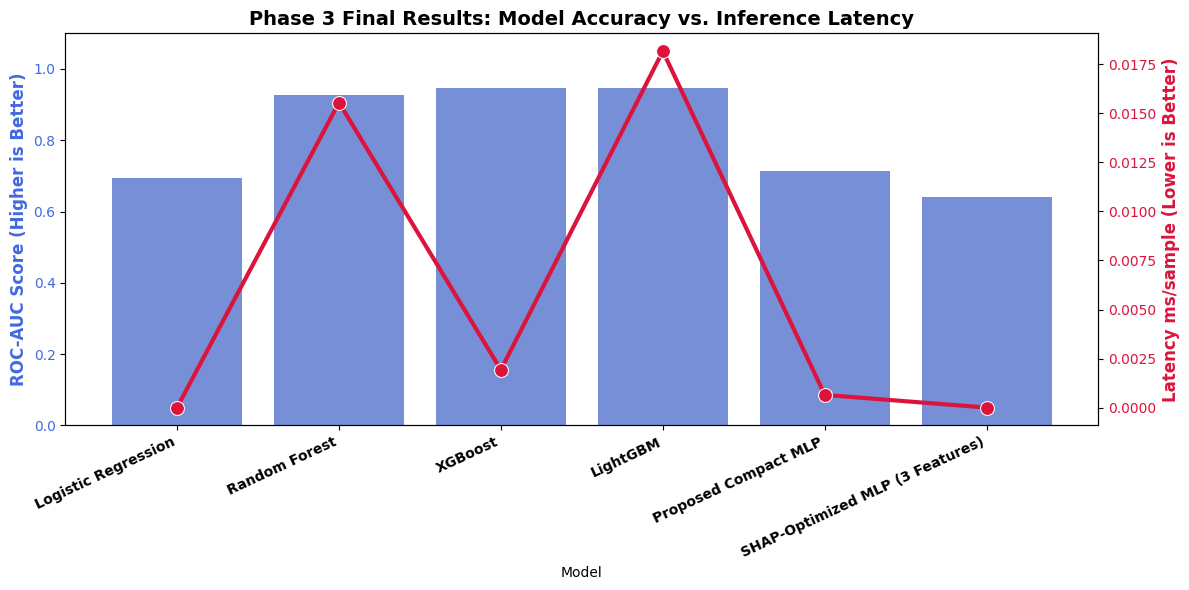

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# FINAL ACCURACY VS LATENCY (ALL 6 MODELS)
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar chart for ROC-AUC (Blue)
sns.barplot(x='Model', y='ROC-AUC', data=final_results_df, ax=ax1, color='royalblue', alpha=0.8)
ax1.set_ylabel('ROC-AUC Score (Higher is Better)', color='royalblue', fontweight='bold', fontsize=12)
ax1.set_ylim(0, 1.1)
ax1.tick_params(axis='y', labelcolor='royalblue')

# Line chart for Latency on secondary Y-axis (Red)
ax2 = ax1.twinx()
sns.lineplot(x='Model', y='Latency (ms)', data=final_results_df, ax=ax2, color='crimson', marker='o', linewidth=3, markersize=10)
ax2.set_ylabel('Latency ms/sample (Lower is Better)', color='crimson', fontweight='bold', fontsize=12)
ax2.tick_params(axis='y', labelcolor='crimson')

plt.title('Phase 3 Final Results: Model Accuracy vs. Inference Latency', fontweight='bold', fontsize=14)

# Rotating the x-labels a bit more so all 6 model names fit perfectly
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=25, ha='right', fontweight='bold')

plt.tight_layout()
plt.show()